In [1]:
import pycobolt
import time
import numpy as np
import matplotlib.pyplot as plt

laser = pycobolt.CoboltLaser(port='COM8') # Creates a new Cobolt Laser object.

def laser_routine(laser, pw, time_heat, time_cycle, n_cycles):
    laser.constant_power(pw)
    times = np.zeros(n_cycles)
    try:
        # Turn the laser on for time_heat seconds
        t1 = time.time()
        laser.turn_on()
        time.sleep(time_heat)
        times[0] = time.time() - t1 - time_heat
        # Perform 100 cycles of turning the laser off and on with time durations of time_cycle seconds each
        for k in range(n_cycles):
            laser.turn_off()
            time.sleep(time_cycle)
            laser.turn_on()
            time.sleep(time_cycle)
            times[k+1] = time.time() - t1 - time_heat - 2*(k+1)*time_cycle
    finally:
        # Ensure the laser is turned off and the connection is closed at the end of the routine
        laser.turn_off()
        return times

In [2]:
power = 10 # Laser power in mW (max is 125)
time_1 = 120.0  # Time of first  irradiation in seconds
time_2 = .0 # Time of each cycle ON/OFF in seconds
n_cycles = 0 # Number of cycles ON/OFF

t_var = laser_routine(laser, power, time_1, time_2, n_cycles)



In [26]:
power = 100 # Laser power in mW (max is 125)
time_1 = 0.0  # Time of first  irradiation in seconds
time_2 = 1.0 # Time of each cycle ON/OFF in seconds
n_cycles = 10 # Number of cycles ON/OFF

t_var = laser_routine(laser, power, time_1, time_2, n_cycles)



0.014271676540374756 0.039141178131103516


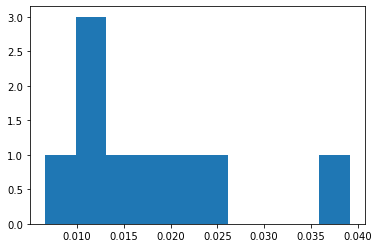

In [22]:
var = np.diff(t_var)
print(np.mean(var[var<0.025]),np.mean(var[var>0.025]))
plt.hist(np.diff(t_var),bins=10);

In [3]:
laser.disconnect()

In [93]:
laser.digital_modulation(1)

'OK'

In [96]:
laser.get_modulation_power()

100.0

In [95]:
laser.set_modulation_power(100)

'OK'

In [97]:
laser.on_off_modulation(1)

'OK'

In [8]:
laser.turn_on()

RuntimeError: Error: write failed

In [7]:
laser.turn_off()

RuntimeError: Error: write failed

In [6]:
laser.disconnect

<bound method CoboltLaser.disconnect of <pycobolt.pycobolt.Cobolt06MLD object at 0x0000017BFCAC5100>>